In [ ]:
!pip install torch torchvision
!pip install monai[all]
!pip install scikit-learn pandas nibabel

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, SubsetRandomSampler
import torch.hub

import monai
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityRanged,
    Resized, RandFlipd, RandRotate90d, ToTensord
)
from monai.networks.nets import resnet10


import pandas as pd
import numpy as np
import os, re, pickle
from pathlib import Path
import nibabel as nib
from typing import List, Optional, Dict, Tuple

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.impute import SimpleImputer

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

In [ ]:

BASE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/lung_cancer/")
LABELS_CSV = BASE_DIR / "labels_TTF1_CK7.csv"
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
RADIOMICS_DIR = BASE_DIR / "radiomics_ct"
SCALER_PATH = BASE_DIR / "radiomics_scaler_monai.pkl"
MODEL_SAVE_DIR = BASE_DIR / "monai_models"

MODEL_SAVE_DIR.mkdir(exist_ok=True)

PREFERRED_CT_SOURCE = "cropped_nifti"
TARGET_SHAPE = (128, 128, 128)
RADIOMICS_DIM = 107
EMBEDDING_DIM = 128

BATCH_SIZE = 2
EPOCHS = 30
LR = 1e-4
N_FOLDS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Se va folosi dispozitivul: {DEVICE}")

Se va folosi dispozitivul: cuda


In [ ]:
def _norm_code(x: str) -> str:
    """Extrage doar cifrele din ID (ex: '2011 ' -> '2011')."""
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred=PREFERRED_CT_SOURCE):
    candidates_order = {
        "cropped_nifti": ["ct_cropped_nifti_path", "ct_nifti_path", "ct_cropped_npy_path", "ct_npy_path"],
        "cropped_npy": ["ct_cropped_npy_path", "ct_npy_path", "ct_cropped_nifti_path", "ct_nifti_path"],
        "nifti": ["ct_nifti_path", "ct_cropped_nifti_path", "ct_npy_path", "ct_cropped_npy_path"],
        "npy": ["ct_npy_path", "ct_cropped_npy_path", "ct_nifti_path", "ct_cropped_nifti_path"],
    }[preferred]

    chosen_col, chosen_path = None, None
    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                chosen_col, chosen_path = col, p
                break
    return chosen_col, chosen_path

def _build_radiomics_path(code: str) -> str:
    p = RADIOMICS_DIR / f"{code}_radiomics.txt"
    return str(p)

def _exists(p: str) -> bool:
    return (p is not None) and os.path.exists(p)

def load_labels(labels_csv: str) -> pd.DataFrame:
    df = pd.read_csv(labels_csv, dtype=str)
    for col in ["TTF1", "CK7"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Code"] = df["Code"].astype(str).apply(_norm_code)
    return df

def load_manifest(manifest_csv: str) -> pd.DataFrame:
    m = pd.read_csv(manifest_csv, dtype=str)
    m.columns = [c.strip() for c in m.columns]
    if "Code" not in m.columns:
        alt = [c for c in m.columns if c.lower() == "code"]
        if alt:
            m.rename(columns={alt[0]: "Code"}, inplace=True)
    m["Code"] = m["Code"].astype(str).apply(_norm_code)
    return m

In [ ]:
def build_data_index(labels: pd.DataFrame, manifest: pd.DataFrame, preferred=PREFERRED_CT_SOURCE) -> pd.DataFrame:
    use_labels = labels.dropna(subset=["TTF1", "CK7"]).copy()
    idx = use_labels.merge(manifest, on="Code", how="left", suffixes=("", ""))

    chosen_cols, chosen_paths = [], []
    for _, row in idx.iterrows():
        col, path = _pick_ct_path(row, preferred=preferred)
        chosen_cols.append(col)
        chosen_paths.append(path)

    idx["ct_path"] = chosen_paths
    idx["radiomics_path"] = idx["Code"].apply(_build_radiomics_path)
    idx["ct_exists"] = idx["ct_path"].apply(_exists)
    idx["radiomics_exists"] = idx["radiomics_path"].apply(_exists)

    idx_ok = idx[(idx["ct_exists"]) & (idx["radiomics_exists"])].copy()

    idx_ok['stratify_key'] = idx_ok['TTF1'].astype(str) + "_" + idx_ok['CK7'].astype(str)

    return idx_ok

labels_df   = load_labels(LABELS_CSV)
manifest_df = load_manifest(MANIFEST_CSV)
data_index = build_data_index(labels_df, manifest_df, preferred=PREFERRED_CT_SOURCE)

print(f"Am găsit {len(data_index)} pacienți cu CT, Radiomics și etichete.")
print("Distribuția claselor pentru stratificare:")
print(data_index['stratify_key'].value_counts())

Am găsit 87 pacienți cu CT, Radiomics și etichete.
Distribuția claselor pentru stratificare:
stratify_key
1_0    31
1_1    30
0_0    14
0_1    12
Name: count, dtype: int64


In [ ]:
def load_radiomics_features(path: str):
    feats = {}
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            k = k.strip()
            v = v.strip()
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k] = val
            except Exception:
                continue
    return feats

def build_radiomics_matrix(df: pd.DataFrame):
    rows = []
    for _, row in df.iterrows():
        feats = load_radiomics_features(row["radiomics_path"])
        feats["Code"] = row["Code"]
        rows.append(feats)

    r_df = pd.DataFrame(rows)

    feature_cols = [c for c in r_df.columns if c != "Code"]
    imputer = SimpleImputer(strategy='mean')
    r_df[feature_cols] = imputer.fit_transform(r_df[feature_cols])

    return r_df, feature_cols

In [ ]:
radiomics_df, feature_cols = build_radiomics_matrix(data_index)

data_merged = data_index.merge(radiomics_df, on="Code", how="left")

X_radio = data_merged[feature_cols].astype(np.float32).values

scaler = StandardScaler()
X_radio_scaled = scaler.fit_transform(X_radio).astype(np.float32)

with open(SCALER_PATH, "wb") as f:
    pickle.dump(scaler, f)

print(f"Matricea Radiomics (X_radio) are dimensiunea: {X_radio_scaled.shape}")

Matricea Radiomics (X_radio) are dimensiunea: (87, 107)


In [ ]:
data_list_monai = []
y_labels_monai = []

for idx, row in data_merged.iterrows():
    data_list_monai.append({
        "ct_path": row["ct_path"],
        "radiomics_index": idx,
        "label_ttf1": row["TTF1"],
        "label_ck7": row["CK7"]
    })
    y_labels_monai.append(row["stratify_key"])

y_labels_monai = np.array(y_labels_monai)

print(f"Am creat lista de dicționare pentru MONAI (total {len(data_list_monai)} eșantioane).")

Am creat lista de dicționare pentru MONAI (total 87 eșantioane).


In [ ]:
train_transforms = Compose([
    LoadImaged(keys=["ct_path"]),
    EnsureChannelFirstd(keys=["ct_path"]),
    ScaleIntensityRanged(keys=["ct_path"], a_min=-1000, a_max=400, b_min=0.0, b_max=1.0, clip=True),
    Resized(keys=["ct_path"], spatial_size=TARGET_SHAPE, mode="trilinear"),

    RandFlipd(keys=["ct_path"], prob=0.5, spatial_axis=2),
    RandRotate90d(keys=["ct_path"], prob=0.5, max_k=3, spatial_axes=(0, 1)),


    ToTensord(keys=["ct_path"])
])

val_transforms = Compose([
    LoadImaged(keys=["ct_path"]),
    EnsureChannelFirstd(keys=["ct_path"]),
    ScaleIntensityRanged(keys=["ct_path"], a_min=-1000, a_max=400, b_min=0.0, b_max=1.0, clip=True),
    Resized(keys=["ct_path"], spatial_size=TARGET_SHAPE, mode="trilinear"),
    ToTensord(keys=["ct_path"])
])

In [ ]:
class CTRadiomicsDataset(Dataset):
    def __init__(self, data_list, radiomics_matrix, transforms):
        self.data_list = data_list
        self.radiomics_matrix = radiomics_matrix
        self.transforms = transforms

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        item = self.data_list[idx]
        ct_data = self.transforms(item.copy())
        ct_tensor = ct_data["ct_path"]

        radiomics_idx = item["radiomics_index"]
        radiomics_tensor = torch.tensor(self.radiomics_matrix[radiomics_idx], dtype=torch.float32)

        label_ttf1 = torch.tensor(item["label_ttf1"], dtype=torch.float32)
        label_ck7 = torch.tensor(item["label_ck7"], dtype=torch.float32)

        return {
            "ct": ct_tensor,
            "radiomics": radiomics_tensor,
            "label_ttf1": label_ttf1,
            "label_ck7": label_ck7
        }

In [ ]:
class ModelCTRadiomics(nn.Module):
    def __init__(self, radiomics_dim, embedding_dim=128, pretrained=True):
        super().__init__()

        self.model_ct_backbone = resnet10(spatial_dims=3, n_input_channels=1, num_classes=512)

        if pretrained:
            print("Se încarcă ponderile pre-antrenate MedicalNet (ResNet10)...")
            weights_url = "https://huggingface.co/TencentMedicalNet/MedicalNet-Resnet10/resolve/main/resnet_10_23dataset.pth"

            try:
                model_dict = self.model_ct_backbone.state_dict()
                pretrained_dict = torch.hub.load_state_dict_from_url(
                    weights_url,
                    progress=True,
                    map_location=DEVICE
                )

                pretrained_dict = {k: v for k, v in pretrained_dict.items() if k in model_dict and model_dict[k].shape == v.shape}

                model_dict.update(pretrained_dict)
                self.model_ct_backbone.load_state_dict(model_dict)
                print("Ponderile au fost încărcate cu succes.")
            except Exception as e:
                print(f"Eroare la descărcarea sau încărcarea ponderilor pre-antrenate: {e}")
                print("Modelul va fi antrenat de la zero (from scratch).")

        self.ct_embed = nn.Linear(512, embedding_dim)


        self.mlp_radio = nn.Sequential(
            nn.Linear(radiomics_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, embedding_dim),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.fusion_head = nn.Sequential(
            nn.Linear(embedding_dim * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.head_ttf1 = nn.Linear(128, 1)
        self.head_ck7 = nn.Linear(128, 1)

    def forward(self, ct_volume, radio_features):
        x_ct = self.model_ct_backbone(ct_volume)
        x_ct = self.ct_embed(x_ct)

        x_radio = self.mlp_radio(radio_features)

        z = torch.cat([x_ct, x_radio], dim=1)
        z = self.fusion_head(z)

        out_ttf1 = self.head_ttf1(z)
        out_ck7 = self.head_ck7(z)

        return {"TTF1": out_ttf1, "CK7": out_ck7}

In [ ]:
def train_one_epoch(model, loader, optimizer, loss_fn_ttf1, loss_fn_ck7, device):
    model.train()
    total_loss = 0

    for batch in loader:
        ct = batch["ct"].to(device)
        radiomics = batch["radiomics"].to(device)
        labels_ttf1 = batch["label_ttf1"].unsqueeze(1).to(device)
        labels_ck7 = batch["label_ck7"].unsqueeze(1).to(device)

        # Forward pass
        optimizer.zero_grad()
        predictions = model(ct, radiomics)

        loss1 = loss_fn_ttf1(predictions["TTF1"], labels_ttf1)
        loss2 = loss_fn_ck7(predictions["CK7"], labels_ck7)
        loss = loss1 + loss2

        # Backward pass
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

def validate_one_epoch(model, loader, loss_fn_ttf1, loss_fn_ck7, device):
    model.eval()
    total_loss = 0
    all_preds_ttf1, all_labels_ttf1 = [], []
    all_preds_ck7, all_labels_ck7 = [], []

    with torch.no_grad():
        for batch in loader:
            ct = batch["ct"].to(device)
            radiomics = batch["radiomics"].to(device)
            labels_ttf1 = batch["label_ttf1"].unsqueeze(1).to(device)
            labels_ck7 = batch["label_ck7"].unsqueeze(1).to(device)

            predictions = model(ct, radiomics)

            # Loss
            loss1 = loss_fn_ttf1(predictions["TTF1"], labels_ttf1)
            loss2 = loss_fn_ck7(predictions["CK7"], labels_ck7)
            loss = loss1 + loss2
            total_loss += loss.item()

            preds_ttf1_prob = torch.sigmoid(predictions["TTF1"]).cpu().numpy()
            preds_ck7_prob = torch.sigmoid(predictions["CK7"]).cpu().numpy()

            all_preds_ttf1.extend(preds_ttf1_prob)
            all_labels_ttf1.extend(labels_ttf1.cpu().numpy())
            all_preds_ck7.extend(preds_ck7_prob)
            all_labels_ck7.extend(labels_ck7.cpu().numpy())

    all_preds_ttf1 = (np.array(all_preds_ttf1) >= 0.5).astype(int)
    all_preds_ck7 = (np.array(all_preds_ck7) >= 0.5).astype(int)

    metrics = {
        "val_loss": total_loss / len(loader),
        "ttf1_acc": accuracy_score(all_labels_ttf1, all_preds_ttf1),
        "ttf1_f1": f1_score(all_labels_ttf1, all_preds_ttf1),
        "ck7_acc": accuracy_score(all_labels_ck7, all_preds_ck7),
        "ck7_f1": f1_score(all_labels_ck7, all_preds_ck7)
    }
    return metrics

In [ ]:

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_results = []

loss_fn_ttf1 = nn.BCEWithLogitsLoss().to(DEVICE)
loss_fn_ck7 = nn.BCEWithLogitsLoss().to(DEVICE)

for fold, (train_indices, val_indices) in enumerate(skf.split(data_list_monai, y_labels_monai)):
    print(f"\n--- ÎNCEPUT FOLD {fold+1}/{N_FOLDS} ---")

    train_dataset = CTRadiomicsDataset(
        data_list=[data_list_monai[i] for i in train_indices],
        radiomics_matrix=X_radio_scaled,
        transforms=train_transforms
    )
    val_dataset = CTRadiomicsDataset(
        data_list=[data_list_monai[i] for i in val_indices],
        radiomics_matrix=X_radio_scaled,
        transforms=val_transforms
    )

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    model = ModelCTRadiomics(radiomics_dim=RADIOMICS_DIM, embedding_dim=EMBEDDING_DIM, pretrained=True).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)

    best_val_loss = float('inf')

    for epoch in range(EPOCHS):
        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn_ttf1, loss_fn_ck7, DEVICE)
        val_metrics = validate_one_epoch(model, val_loader, loss_fn_ttf1, loss_fn_ck7, DEVICE)

        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['val_loss']:.4f} | "
              f"TTF1 F1: {val_metrics['ttf1_f1']:.4f} | CK7 F1: {val_metrics['ck7_f1']:.4f}")

        scheduler.step(val_metrics['val_loss'])

        if val_metrics['val_loss'] < best_val_loss:
            best_val_loss = val_metrics['val_loss']
            model_path = MODEL_SAVE_DIR / f"best_model_fold_{fold+1}.pth"
            torch.save(model.state_dict(), model_path)
            print(f"Modelul pentru FOLD {fold+1} a fost salvat la {model_path}")

    fold_results.append(val_metrics)

print("\n--- Antrenament K-Fold finalizat ---")


--- ÎNCEPUT FOLD 1/5 ---
Se încarcă ponderile pre-antrenate MedicalNet (ResNet10)...
Downloading: "https://huggingface.co/TencentMedicalNet/MedicalNet-Resnet10/resolve/main/resnet_10_23dataset.pth" to /root/.cache/torch/hub/checkpoints/resnet_10_23dataset.pth


100%|██████████| 54.8M/54.8M [00:01<00:00, 33.5MB/s]


Ponderile au fost încărcate cu succes.
Epoch 1/30 | Train Loss: 1.3521 | Val Loss: 1.3099 | TTF1 F1: 0.8387 | CK7 F1: 0.2000
Modelul pentru FOLD 1 a fost salvat la /content/drive/MyDrive/Colab Notebooks/lung_cancer/monai_models/best_model_fold_1.pth
Epoch 2/30 | Train Loss: 1.3393 | Val Loss: 1.2873 | TTF1 F1: 0.8387 | CK7 F1: 0.0000
Modelul pentru FOLD 1 a fost salvat la /content/drive/MyDrive/Colab Notebooks/lung_cancer/monai_models/best_model_fold_1.pth
Epoch 3/30 | Train Loss: 1.3248 | Val Loss: 1.2912 | TTF1 F1: 0.8387 | CK7 F1: 0.0000
Epoch 4/30 | Train Loss: 1.3201 | Val Loss: 1.2882 | TTF1 F1: 0.8387 | CK7 F1: 0.0000
Epoch 5/30 | Train Loss: 1.3077 | Val Loss: 1.2879 | TTF1 F1: 0.8387 | CK7 F1: 0.0000
Epoch 6/30 | Train Loss: 1.3097 | Val Loss: 1.2889 | TTF1 F1: 0.8387 | CK7 F1: 0.0000
Epoch 7/30 | Train Loss: 1.3013 | Val Loss: 1.2863 | TTF1 F1: 0.8387 | CK7 F1: 0.0000
Modelul pentru FOLD 1 a fost salvat la /content/drive/MyDrive/Colab Notebooks/lung_cancer/monai_models/best_m

In [ ]:
mean_loss = np.mean([r['val_loss'] for r in fold_results])
mean_ttf1_acc = np.mean([r['ttf1_acc'] for r in fold_results])
mean_ttf1_f1 = np.mean([r['ttf1_f1'] for r in fold_results])
mean_ck7_acc = np.mean([r['ck7_acc'] for r in fold_results])
mean_ck7_f1 = np.mean([r['ck7_f1'] for r in fold_results])

std_ttf1_acc = np.std([r['ttf1_acc'] for r in fold_results])
std_ck7_f1 = np.std([r['ck7_f1'] for r in fold_results])


print("--- REZULTATE MEDII K-FOLD CROSS-VALIDATION ---")
print(f"Val Loss Mediu: {mean_loss:.4f}")
print(f"TTF1 Acuratețe Medie: {mean_ttf1_acc:.4f} ± {std_ttf1_acc:.4f}")
print(f"TTF1 F1-Score Mediu: {mean_ttf1_f1:.4f}")
print(f"CK7 Acuratețe Medie: {mean_ck7_acc:.4f}")
print(f"CK7 F1-Score Mediu: {mean_ck7_f1:.4f} ± {std_ck7_f1:.4f}")

--- REZULTATE MEDII K-FOLD CROSS-VALIDATION ---
Val Loss Mediu:      1.3031
TTF1 Acuratețe Medie: 0.7013 ± 0.0184
TTF1 F1-Score Mediu:  0.8243
CK7 Acuratețe Medie:  0.5268
CK7 F1-Score Mediu:   0.2610 ± 0.2029


Se generează matricele de confuzie pentru ultimul FOLD...

TTF1 — binary metrics (threshold=0.50)
Accuracy:  0.7059
Precision: 0.7059
Recall:    1.0000
F1-score:  0.8276
Confusion matrix [[TN FP] [FN TP]]:
[[ 0  5]
 [ 0 12]]


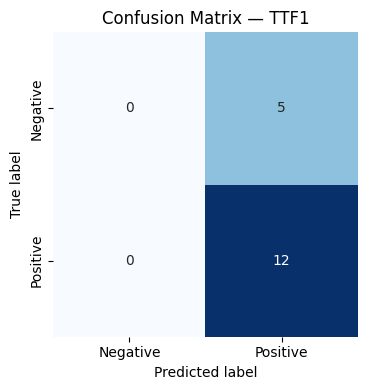

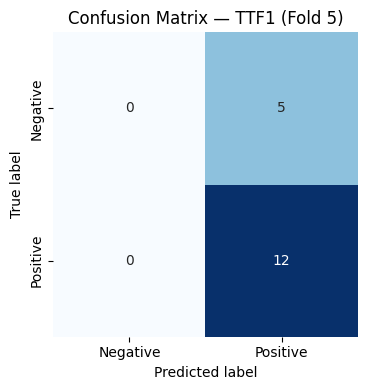


CK7 — binary metrics (threshold=0.50)
Accuracy:  0.5294
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Confusion matrix [[TN FP] [FN TP]]:
[[9 0]
 [8 0]]


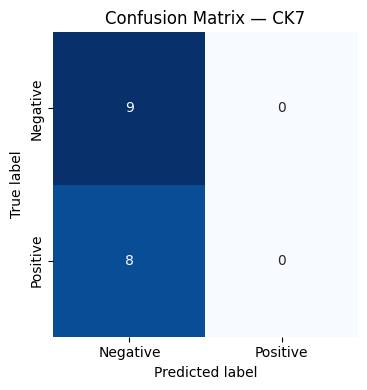

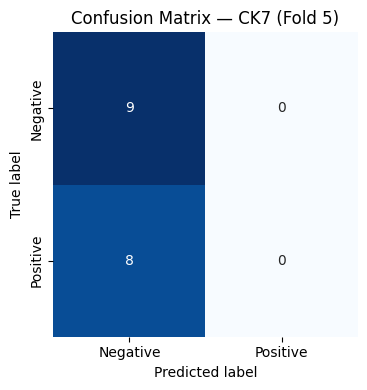

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("Se generează matricele de confuzie pentru ultimul FOLD...")

model.load_state_dict(torch.load(MODEL_SAVE_DIR / f"best_model_fold_{N_FOLDS}.pth"))
val_metrics_final = validate_one_epoch(model, val_loader, loss_fn_ttf1, loss_fn_ck7, DEVICE)

all_preds_ttf1, all_labels_ttf1 = [], []
all_preds_ck7, all_labels_ck7 = [], []

model.eval()
with torch.no_grad():
    for batch in val_loader:
        ct = batch["ct"].to(DEVICE)
        radiomics = batch["radiomics"].to(DEVICE)
        labels_ttf1 = batch["label_ttf1"].cpu().numpy()
        labels_ck7 = batch["label_ck7"].cpu().numpy()

        predictions = model(ct, radiomics)
        preds_ttf1_prob = torch.sigmoid(predictions["TTF1"]).cpu().numpy()
        preds_ck7_prob = torch.sigmoid(predictions["CK7"]).cpu().numpy()

        all_preds_ttf1.extend(preds_ttf1_prob)
        all_labels_ttf1.extend(labels_ttf1)
        all_preds_ck7.extend(preds_ck7_prob)
        all_labels_ck7.extend(labels_ck7)

y_pred_ttf1 = (np.array(all_preds_ttf1) >= 0.5).astype(int).ravel()
y_true_ttf1 = np.array(all_labels_ttf1).astype(int).ravel()
y_pred_ck7 = (np.array(all_preds_ck7) >= 0.5).astype(int).ravel()
y_true_ck7 = np.array(all_labels_ck7).astype(int).ravel()


def plot_confusion_matrix_custom(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name} (Fold {N_FOLDS})")
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics (threshold={0.5:.2f})")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1, y_pred_ttf1, "TTF1")
plot_confusion_matrix_custom(y_true_ttf1, y_pred_ttf1, "TTF1")

print_binary_metrics(y_true_ck7, y_pred_ck7, "CK7")
plot_confusion_matrix_custom(y_true_ck7, y_pred_ck7, "CK7")